<div style="background:#14161c;color:#f2f4f8;border-left:5px solid #70e2d2;padding:24px 28px;border-radius:8px">
  <small style="letter-spacing:2px;color:#70e2d2">MASTER DATA & IA · COMPUTER VISION</small>
  <h1 style="color:#fff;margin:12px 0 8px">La vision ne suffit pas.</h1>
  <p style="color:#d9dde6;margin:0">Évaluer la <b>génération d'images</b>, la <b>détection</b> et le <b>suivi d'objets</b>.</p>
</div>


| Partie | Métriques | Slides |
|:--|:--|:--|
| 01 · Image Generation | FID, KID, CLIPScore | 3–4 |
| 02 · Object Detection | IoU, précision, rappel, AP, mAP | 5–6 |
| 03 · Object Tracking | MOTA, IDF1, HOTA | 7–8 |

## 00 / Préparation


In [1]:
# Bibliothèques pour les calculs, les appariements et les graphiques.
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
from scipy.optimize import linear_sum_assignment
from collections import Counter
from PIL import Image, ImageDraw
from matplotlib.patches import Rectangle

# Graines fixes : mêmes exemples à chaque exécution.
rng = np.random.default_rng(42)

# Palette inspirée de la présentation Dark Editorial.
BG, FG, AQUA, LILAC, CORAL = '#151820', '#f4f6fa', '#71dfd2', '#b69cff', '#ff9b8a'

def dark(ax):
    """Rend les graphiques lisibles sur un fond sombre."""
    ax.set_facecolor(BG)
    ax.tick_params(colors=FG)
    for edge in ax.spines.values():
        edge.set_color('#526070')
    ax.xaxis.label.set_color(FG)
    ax.yaxis.label.set_color(FG)
    ax.title.set_color(FG)

## 01 / IMAGE GENERATION
### FID et KID · comparer des distributions, pas une image isolée

Un encodeur d'images produit des **caractéristiques** (features) pour chaque image. Les métriques comparent la distribution de ces caractéristiques entre **images de référence** et **images générées**.

- **FID ↓** : différence de moyenne et de covariance entre distributions.
- **KID ↓** : différence entre distributions mesurée par un noyau (MMD²).

**Démonstration :** points 2D simulant des features. Le vrai FID/KID standard utilise normalement des features d'un réseau Inception.

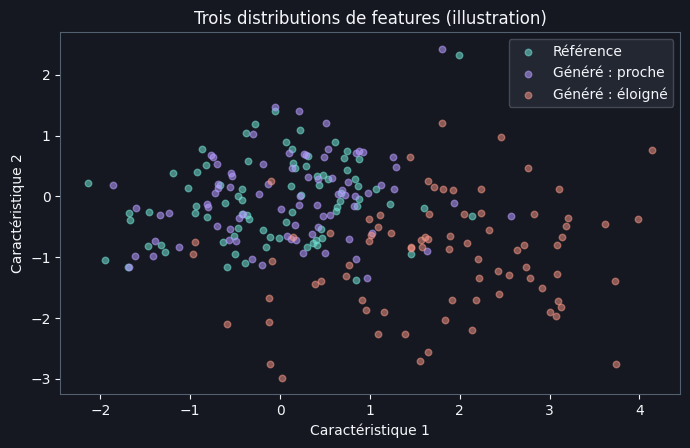

In [2]:
# 80 vecteurs fictifs d'images de référence dans un espace de caractéristiques 2D.
reelles = rng.normal(loc=[0, 0], scale=[1.0, 0.8], size=(80, 2))

# Un générateur "proche" conserve presque la même distribution.
proches = reelles + rng.normal(0, 0.18, size=reelles.shape) + [0.12, 0.04]

# Un générateur "éloigné" décale davantage la distribution.
eloignees = rng.normal(loc=[1.8, -1.0], scale=[1.2, 0.85], size=(80, 2))

# Visualisation des trois ensembles de caractéristiques.
fig, ax = plt.subplots(figsize=(8, 4.7), facecolor=BG)
ax.scatter(*reelles.T, s=22, alpha=.55, color=AQUA, label='Référence')
ax.scatter(*proches.T, s=22, alpha=.55, color=LILAC, label='Généré : proche')
ax.scatter(*eloignees.T, s=22, alpha=.5, color=CORAL, label='Généré : éloigné')
dark(ax)
ax.set(xlabel='Caractéristique 1', ylabel='Caractéristique 2', title='Trois distributions de features (illustration)')
leg = ax.legend(facecolor='#272b37', edgecolor='#4f5360')
for text in leg.get_texts(): text.set_color(FG)
plt.show()

In [3]:
def fid_features(x, y):
    """Formule FID sur des vecteurs : ici sans extraction Inception."""
    # Moyennes et matrices de covariance des deux ensembles.
    mu_x, mu_y = x.mean(axis=0), y.mean(axis=0)
    cov_x, cov_y = np.cov(x, rowvar=False), np.cov(y, rowvar=False)

    # Distance entre moyennes + distance entre covariances.
    racine = sqrtm(cov_x @ cov_y).real
    valeur = np.sum((mu_x - mu_y)**2) + np.trace(cov_x + cov_y - 2 * racine)
    return max(float(valeur), 0.0)  # Corrige un éventuel -epsilon numérique.


def kid_features(x, y):
    """MMD² non biaisé avec noyau polynomial, principe du KID."""
    # k(x,y) = (x·y/d + 1)^3, avec d = nombre de caractéristiques.
    d = x.shape[1]
    kxx = (x @ x.T / d + 1)**3
    kyy = (y @ y.T / d + 1)**3
    kxy = (x @ y.T / d + 1)**3
    n, m = len(x), len(y)

    # On retire la diagonale pour l'estimateur non biaisé.
    return float((kxx.sum() - np.trace(kxx))/(n*(n-1))
                 + (kyy.sum() - np.trace(kyy))/(m*(m-1))
                 - 2*kxy.mean())

# Comparer deux candidats sur les mêmes références.
for nom, candidat in [('Proche', proches), ('Éloigné', eloignees)]:
    print(f'{nom:8s} | FID (features) = {fid_features(reelles, candidat):6.3f}'
          f' | KID (features) = {kid_features(reelles, candidat):7.3f}')

print('Interprétation : valeurs plus petites = distributions plus similaires.')

Proche   | FID (features) =  0.021 | KID (features) =  -0.103
Éloigné  | FID (features) =  4.390 | KID (features) =  51.551
Interprétation : valeurs plus petites = distributions plus similaires.
NB : un KID estimé peut être légèrement négatif (estimateur non biaisé).


**Interprétation.** L'ensemble « proche » devrait obtenir des scores plus faibles que l'ensemble « éloigné ». **FID/KID évaluent des ensembles d'images** ; ils ne disent pas si une image donnée respecte précisément un prompt.

### CLIPScore · vérifier le sens du prompt
Prompt de la présentation : **« Une lune violette au-dessus de la ville »**. Deux images schématiques permettent de distinguer esthétique et fidélité au texte.

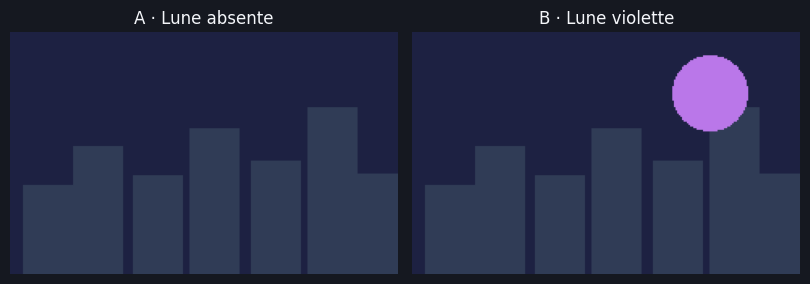

Score conceptuel A : 70.7/100
Score conceptuel B : 100.0/100
Interprétation : B aligne mieux les concepts du prompt. Ceci n’est pas un vrai CLIPScore.


In [13]:
def dessiner_ville(avec_lune):
    img = Image.new('RGB', (240, 150), (29, 33, 66))
    d = ImageDraw.Draw(img)
    # Silhouettes simplifiées des immeubles.
    for x, h in [(8,55),(39,79),(76,61),(111,90),(149,70),(184,103),(215,62)]:
        d.rectangle((x, 150-h, x+30, 149), fill=(48, 60, 86))
    # La seconde image suit le prompt grâce à une lune violette.
    if avec_lune:
        d.ellipse((161, 15, 207, 61), fill=(186, 119, 233))
    return img

image_A, image_B = dessiner_ville(False), dessiner_ville(True)
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2), facecolor=BG)
for ax, img, titre in zip(axes, [image_A, image_B], ['A · Lune absente', 'B · Lune violette']):
    ax.imshow(img); ax.set_title(titre, color=FG); ax.axis('off')
plt.tight_layout(); plt.show()

# Illustration de la formule CLIPScore = max(100 × cos(image, texte), 0).
# Ces vecteurs sont inventés pour comprendre le cosinus : ce ne sont PAS des embeddings CLIP.
texte = np.array([1.0, 1.0])            # Concepts : ville + lune violette.
img_A = np.array([1.0, 0.0])            # Ville seulement.
img_B = np.array([1.0, 1.0])            # Ville + lune violette.

def score_cosinus(image, texte):
    cos = np.dot(image, texte) / (np.linalg.norm(image) * np.linalg.norm(texte))
    return max(100 * cos, 0)            # Forme du CLIPScore ; vecteurs fictifs.

print(f'Score conceptuel A : {score_cosinus(img_A, texte):.1f}/100')
print(f'Score conceptuel B : {score_cosinus(img_B, texte):.1f}/100')
print('Interprétation : B aligne mieux les concepts du prompt.')

**Interprétation.** Ici, B correspond mieux au prompt. Un **vrai CLIPScore** calcule ce cosinus avec les embeddings d'un **modèle CLIP préentraîné** (pas avec les vecteurs inventés ci-dessus). Un score élevé mesure l'alignement sémantique, mais **ne garantit pas** la qualité visuelle ou l'exactitude de tous les détails.

## 02 / OBJECT DETECTION

### IoU · est-ce au bon endroit ?

L'**Intersection over Union (IoU)** mesure le recouvrement de deux boîtes :

$$
\mathrm{IoU} = \frac{\mathrm{aire}(GT \cap P)}{\mathrm{aire}(GT \cup P)}
$$
aire = surface
l'union est la surface totale coverte par les deux boîtes.\
résultat = 0 => aucun chevauchement\
résultat = 0.4 => cheveauchement partiel\
résultat = 0.7 => bon cheveauchement\
résultat = 1 => correspondance parfaite.

Avec un seuil **IoU ≥ 0,50**, une prédiction peut être considérée comme correcte **si** elle a aussi la bonne classe et qu'elle est appariée à un objet non encore détecté.

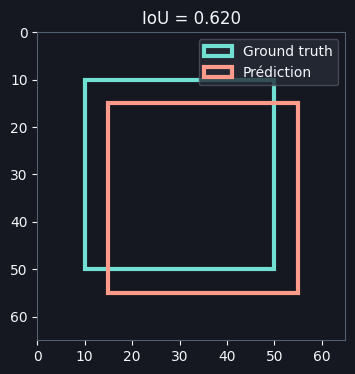

IoU ≥ 0,50 : True | IoU ≥ 0,75 : False


In [5]:
def iou(a, b):
    """IoU entre deux boîtes [xmin, ymin, xmax, ymax]."""
    # Coordonnées du rectangle commun.
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(x2 - x1, 0) * max(y2 - y1, 0)

    # Aires individuelles et union.
    aire_a = (a[2]-a[0]) * (a[3]-a[1])
    aire_b = (b[2]-b[0]) * (b[3]-b[1])
    union = aire_a + aire_b - intersection
    return intersection / union if union > 0 else 0.0

# Une annotation (GT) et une prédiction légèrement décalée.
gt_box = [10, 10, 50, 50]
pred_box = [15, 15, 55, 55]
recouvrement = iou(gt_box, pred_box)

# Dessiner les deux boîtes.
fig, ax = plt.subplots(figsize=(5.1, 4), facecolor=BG)
ax.add_patch(Rectangle((10,10),40,40, fill=False, linewidth=3, edgecolor=AQUA, label='Ground truth'))
ax.add_patch(Rectangle((15,15),40,40, fill=False, linewidth=3, edgecolor=CORAL, label='Prédiction'))
ax.set_xlim(0,65); ax.set_ylim(65,0); ax.set_aspect('equal'); dark(ax)
ax.set_title(f'IoU = {recouvrement:.3f}', color=FG)
leg=ax.legend(facecolor='#272b37', edgecolor='#4f5360')
for t in leg.get_texts(): t.set_color(FG)
plt.show()
print(f'IoU ≥ 0,50 : {recouvrement >= 0.50} | IoU ≥ 0,75 : {recouvrement >= 0.75}')

**Interprétation.** La même prédiction peut être un **TP à IoU=0,50**, mais un **FP à IoU=0,75**. Le seuil d'IoU change donc l'exigence sur la localisation.

### Précision, rappel et mAP · plus qu'un seul seuil

- **Précision = TP / (TP + FP)** : parmi les détections proposées, combien sont correctes ?
- **Rappel = TP / (TP + FN)** : parmi les objets présents, combien sont retrouvés ?
- **AP** : aire interpolée sous la courbe précision–rappel.
- **mAP@0,50:0,95** : moyenne des AP sur 10 seuils d'IoU (et sur les classes en évaluation multi-classe).

In [6]:
# Une seule image, une seule classe, trois objets annotés.
gt_boxes = np.array([[10,10,50,50], [57,12,91,47], [25,60,59,94]], dtype=float)

# Cinq propositions : boîtes + scores de confiance décroissants.
pred_boxes = np.array([[12,12,50,50], [65,59,95,89], [56,12,91,48],
                       [24,60,60,94], [5,65,21,88]], dtype=float)
scores = np.array([0.98, 0.92, 0.84, 0.73, 0.55])

def evaluer(iou_min=0.50, score_min=0.0):
    """Appariement glouton selon la confiance, pour UNE classe et UNE image."""
    # On parcourt les prédictions dans l'ordre des scores, sans réutiliser une GT.
    deja_vues = set()
    tp, fp = [], []
    for idx in np.argsort(-scores):
        if scores[idx] < score_min:
            continue
        recouvrements = [iou(pred_boxes[idx], gt) if j not in deja_vues else -1
                         for j, gt in enumerate(gt_boxes)]
        meilleure = int(np.argmax(recouvrements))
        if recouvrements[meilleure] >= iou_min:
            deja_vues.add(meilleure); tp.append(1); fp.append(0)
        else:
            tp.append(0); fp.append(1)
    return np.asarray(tp), np.asarray(fp), len(gt_boxes) - len(deja_vues)

# Exemple concret au seuil de confiance 0,80.
tp, fp, fn = evaluer(iou_min=0.50, score_min=0.80)
precision = tp.sum() / (tp.sum() + fp.sum())
rappel = tp.sum() / len(gt_boxes)
print(f'TP={tp.sum()}, FP={fp.sum()}, FN={fn}  |  Précision={precision:.3f}  |  Rappel={rappel:.3f}')

TP=2, FP=1, FN=1  |  Précision=0.667  |  Rappel=0.667


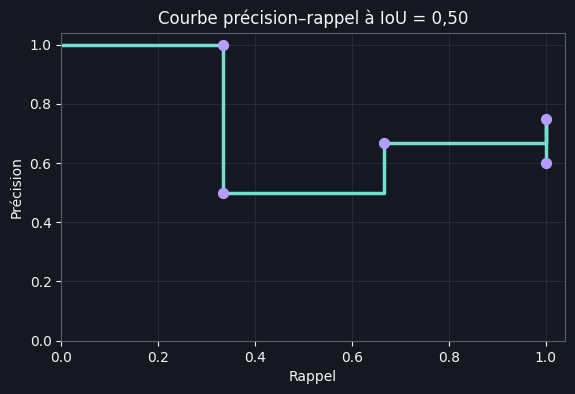

AP@0,50 = 0.834
mAP@0,50:0,95 = 0.751  (une classe, une image)
Interprétation : mAP@0,50:0,95 pénalise davantage les boîtes mal localisées.


In [7]:
def courbe_et_ap(iou_min):
    """Courbe PR et AP interpolée à 101 points (version pédagogique COCO)."""
    tp, fp, _ = evaluer(iou_min=iou_min)
    rappel = np.cumsum(tp) / len(gt_boxes)
    precision = np.cumsum(tp) / (np.cumsum(tp) + np.cumsum(fp))

    # Interpolation à 101 niveaux de rappel : moyenne des meilleures précisions à droite.
    seuils_rappel = np.linspace(0, 1, 101)
    valeurs = [max(precision[rappel >= r], default=0) for r in seuils_rappel]
    return rappel, precision, float(np.mean(valeurs))

rappel_pr, precision_pr, ap50 = courbe_et_ap(0.50)
seuils_iou = np.arange(0.50, 0.951, 0.05)
ap_par_seuil = [courbe_et_ap(s)[2] for s in seuils_iou]
map_5095 = float(np.mean(ap_par_seuil))

# Représenter la relation précision–rappel.
fig, ax = plt.subplots(figsize=(6.5, 4), facecolor=BG)
ax.step(np.r_[0, rappel_pr], np.r_[1, precision_pr], where='post', color=AQUA, linewidth=2.5)
ax.scatter(rappel_pr, precision_pr, color=LILAC, s=50, zorder=3)
ax.set(xlim=(0,1.04), ylim=(0,1.04), xlabel='Rappel', ylabel='Précision',
       title='Courbe précision–rappel à IoU = 0,50')
dark(ax); ax.grid(color='#626b78', alpha=.22)
plt.show()
print(f'AP@0,50 = {ap50:.3f}')
print(f'mAP@0,50:0,95 = {map_5095:.3f}  (une classe, une image)')
print('Interprétation : mAP@0,50:0,95 pénalise davantage les boîtes mal localisées.')

**Interprétation.** La courbe change si l'on fait varier la confiance minimale des détections. Ici, le **mAP multi-seuils** est plus exigeant que l'AP à IoU=0,50. Cette version reprend le principe COCO pour **une image et une classe**, sans couvrir tous les cas du protocole COCO (classes multiples, objets ignorés, différentes échelles, etc.).

## 03 / OBJECT TRACKING
### Détecter n'est pas suivre

Scénario de la présentation : **deux objets**, **trois frames**. Les six positions sont correctement détectées, mais les identifiants prédits sont **inversés à la troisième frame**.

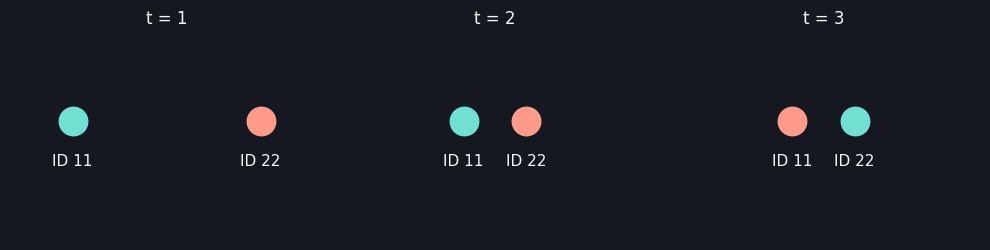

À t=3 : les positions sont justes, mais les ID ont été échangés.


In [8]:
# Identités réelles : les deux objets restent GT1 et GT2 à chaque frame.
positions = [((20,75),(80,75)), ((40,75),(60,75)), ((60,75),(40,75))]
ids_predits = [('11','22'), ('11','22'), ('22','11')]  # Inversion à t = 3.

# Visualisation du problème d'association temporelle.
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), facecolor=BG)
for t, (ax, points, ids) in enumerate(zip(axes, positions, ids_predits), start=1):
    for k, (point, id_pred) in enumerate(zip(points, ids)):
        ax.scatter(*point, s=420, color=[AQUA, CORAL][k], zorder=3)
        ax.text(point[0], point[1]-19, f'ID {id_pred}', ha='center', color=FG, fontsize=11)
    ax.set(xlim=(0,100), ylim=(25,112), title=f't = {t}')
    dark(ax); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()
print('À t=3 : les positions sont justes, mais les ID ont été échangés.')


### MOTA et IDF1 · compter les erreurs, puis évaluer les identités

**MOTA (Multiple Object Tracking Accuracy)**

$$
\mathrm{MOTA} = 1 - \frac{FP + FN + IDSW}{GT}
$$

**IDF1 (Identity F1 Score)**

$$
\mathrm{IDF1} = \frac{2 \cdot IDTP}{2 \cdot IDTP + IDFP + IDFN}
$$

- **MOTA ↑** pénalise les fausses alertes (FP), les objets manqués (FN) et les changements d'identité (IDSW). Il peut être négatif.
- **IDF1 ↑** valorise la conservation cohérente d'une identité tout au long de la séquence.

**Définitions :**
- **GT** : nombre total d'instances d'objets réels sur l'ensemble des frames.
- **IDSW** : nombre de changements d'identité.
- **IDTP** : détections correctement associées à leur identité.
- **IDFP** : associations d'identité incorrectes ou superflues.
- **IDFN** : associations d'identité manquées.

Dans cet exemple, l'appariement spatial de chaque frame est supposé parfait.


In [9]:
# Chaque paire représente une correspondance spatiale (ID réel, ID prédit).
# Frames 1 et 2 : IDs cohérents ; frame 3 : IDs inversés.
frames = [[(1,11), (2,22)], [(1,11), (2,22)], [(1,22), (2,11)]]
correspondances = [pair for frame in frames for pair in frame]

# Calculer les switches : changement d'ID prédit pour un même ID réel.
dernier_id, idsw = {}, 0
for frame in frames:
    for gt_id, pred_id in frame:
        if gt_id in dernier_id and dernier_id[gt_id] != pred_id:
            idsw += 1
        dernier_id[gt_id] = pred_id

# Ici tous les objets sont détectés, donc FP = FN = 0.
GT, FP, FN = len(correspondances), 0, 0
mota = 1 - (FP + FN + idsw) / GT

# IDF1 : trouver l'appariement global optimal entre IDs réels et prédits.
reels_ids, pred_ids = [1,2], [11,22]
cpt = Counter(correspondances)
table = np.array([[cpt[(g,p)] for p in pred_ids] for g in reels_ids])
lignes, colonnes = linear_sum_assignment(-table)  # Maximisation via le signe négatif.
IDTP = int(table[lignes, colonnes].sum())
IDFP, IDFN = GT - IDTP, GT - IDTP
idf1 = 2*IDTP / (2*IDTP + IDFP + IDFN)

print(f'GT={GT} | FP={FP} | FN={FN} | IDSW={idsw}')
print(f'MOTA = {mota:.3f}  |  IDF1 = {idf1:.3f}')
print('Interprétation : 100 % des positions sont justes, mais les ID se dégradent.')

# Le chiffre cité dans la présentation (slide 8) : 50 GT, 2 FP, 4 FN, 1 IDSW.
mota_slide = 1 - (2 + 4 + 1) / 50
print(f'Vérification du mini-exemple de la slide 8 : MOTA = {mota_slide:.0%}')

GT=6 | FP=0 | FN=0 | IDSW=2
MOTA = 0.667  |  IDF1 = 0.667
Interprétation : 100 % des positions sont justes, mais les ID se dégradent.
Vérification du mini-exemple de la slide 8 : MOTA = 86%


### HOTA · équilibrer détection et association

\[ \mathrm{HOTA}_{\alpha}=\sqrt{\mathrm{DetA}_{\alpha}\,\mathrm{AssA}_{\alpha}} \]

- **DetA** : qualité des détections.
- **AssA** : cohérence des associations d'identités.

Nous montrons **HOTA à un seuil illustratif**. Le score officiel utilise un appariement propre à HOTA, puis une moyenne sur plusieurs seuils de localisation (\(\alpha=0{,}05, 0{,}10,\ldots,0{,}95\)).

In [10]:
# Pour chaque paire (GT, ID prédit), compter les frames bien associées.
# Ici, les six détections sont correctes spatialement, mais deux pistes se fragmentent.
nb_par_paire = Counter(correspondances)
nb_par_gt = Counter(gt for gt, _ in correspondances)
nb_par_pred = Counter(pred for _, pred in correspondances)

# AssA : moyenne des IoU d'association sur les vrais positifs.
associations = []
for gt_id, pred_id in correspondances:
    tpa = nb_par_paire[(gt_id, pred_id)]
    fna = nb_par_gt[gt_id] - tpa
    fpa = nb_par_pred[pred_id] - tpa
    associations.append(tpa / (tpa + fna + fpa))

AssA = float(np.mean(associations))
DetA = GT / (GT + FP + FN)
hota_illustratif = np.sqrt(DetA * AssA)

print(f'DetA = {DetA:.3f}  |  AssA = {AssA:.3f}')
print(f'HOTA illustratif à seuil fixe ≈ {hota_illustratif:.3f}')
print('Interprétation : détecter parfaitement (DetA=1) ne suffit pas si AssA est faible.')
print('Pour un benchmark HOTA officiel, utiliser TrackEval.')

DetA = 1.000  |  AssA = 0.400
HOTA illustratif à seuil fixe ≈ 0.632
Interprétation : détecter parfaitement (DetA=1) ne suffit pas si AssA est faible.
Pour un benchmark HOTA officiel, utiliser TrackEval.


## 04 / Synthèse

| Tâche | À vérifier | Métriques principales | Sens |
|:--|:--|:--|:--|
| **Génération** | Distribution + adéquation au prompt | FID / KID + CLIPScore | FID/KID ↓, CLIPScore ↑ |
| **Détection** | Localisation + faux positifs + oublis | IoU, Precision, Recall, mAP | ↑ |
| **Tracking** | Détection + identité dans le temps | MOTA, IDF1, HOTA | ↑ |

